# **Project Report - 10**

# **Bachelor of Computer Applications (BCA)**

#**Semester – V**

####**Sub**: Deep Learning ####

####**Topic:** Overfitting and Underfitting Analysis ####


####**Submitted By** ####

####**Name:** Pragathi BR ####

####**Reg no:** 2411021240037 ####

####**Date of Submission:** 17/10/2026 ####

####**Faculty Name:** Nagasri. P ####

## **Aim**
To build neural network models with different levels of complexity using the Iris dataset and analyze underfitting, appropriate fitting, and overfitting.

## **Introduction**
Overfitting and underfitting are common problems in machine learning and deep learning. Underfitting occurs when a model is too simple to learn important patterns in the data. Overfitting occurs when a model learns the training data too closely but performs poorly on unseen data. Appropriate fitting occurs when a model learns useful patterns and generalizes well.

In this project, three neural network models with different architectures are developed using the Iris dataset. Their training and testing performance is compared to understand how model complexity affects classification.

## **Objectives**
1. Build neural network models with different architectures.
2. Train all models using the same training data.
3. Evaluate the models using the same testing data.
4. Compare training accuracy, testing accuracy, and loss.
5. Identify underfitting, appropriate fitting, and overfitting.
6. Suggest methods to improve model performance.


In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report

tf.keras.utils.set_random_seed(42)

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow version: 2.21.0
Libraries imported successfully!



## **Dataset Description**

The Iris dataset is a classification dataset containing 150 flower samples belonging to three classes: Iris Setosa, Iris Versicolor, and Iris Virginica.

Each sample contains four input features:
1. Sepal length
2. Sepal width
3. Petal length
4. Petal width

The goal is to predict the correct flower class using these four features.


In [24]:
# Load the Iris dataset
iris = load_iris()

X = iris.data
y = iris.target

print("Dataset shape:", X.shape)
print("Target shape:", y.shape)
print("Feature names:", iris.feature_names)
print("Flower classes:", iris.target_names)

# Display the first five samples
df = pd.DataFrame(X, columns=iris.feature_names)
df["Flower Class"] = [iris.target_names[i] for i in y]

display(df.head())

Dataset shape: (150, 4)
Target shape: (150,)
Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Flower classes: ['setosa' 'versicolor' 'virginica']


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Flower Class
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa



## **Data Preprocessing**

The dataset is divided into 70% training data and 30% testing data. The training data is used to teach the models, while the testing data is used to evaluate their performance on unseen samples.

StandardScaler is used to standardize the input features. Stratified splitting maintains the proportion of each flower class in both sets. All models use the same training and testing data for a fair comparison.


In [25]:
# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Standardize features using training data only
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Input features:", X_train.shape[1])

Training samples: 105
Testing samples: 45
Input features: 4



# **Task 1: Build Neural Network Models Using the Iris Dataset**

Three neural network models with different architectures are developed.

### **Model 1: Simple Model**
This model contains an output layer with three neurons and no hidden layer. Its limited learning capacity may cause underfitting.

### **Model 2: Balanced Model**
This model contains one hidden layer with 16 neurons and ReLU activation. It is designed to learn important patterns without unnecessary complexity.

### **Model 3: Complex Model**
This model contains three hidden layers with 128, 128, and 64 neurons. Its higher learning capacity may increase the risk of overfitting.

All models use Softmax activation in the output layer, the Adam optimizer, and sparse categorical cross-entropy loss.


In [26]:
# Model 1: Simple model
def create_simple_model():
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(4,)),
        tf.keras.layers.Dense(3, activation="softmax")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.01),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model


# Model 2: Balanced model
def create_balanced_model():
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(4,)),
        tf.keras.layers.Dense(16, activation="relu"),
        tf.keras.layers.Dense(3, activation="softmax")
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model


# Model 3: Complex model
def create_complex_model():
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(4,)),
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dense(3, activation="softmax")
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model


simple_model = create_simple_model()
balanced_model = create_balanced_model()
complex_model = create_complex_model()



print("All three models created successfully.")

All three models created successfully.



### **Model Summary**

The model summary displays the layers and number of trainable parameters in each neural network. It helps us compare the complexity of the three architectures.


In [27]:
print("SIMPLE MODEL")
simple_model.summary()

print("\nBALANCED MODEL")
balanced_model.summary()

print("\nCOMPLEX MODEL")
complex_model.summary()

SIMPLE MODEL


Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_21 (Dense)                │ (None, 3)              │            15 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15 (60.00 B)

 Trainable params: 15 (60.00 B)

...

Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_24 (Dense)                │ (None, 128)            │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,603 (100.01 KB)

 Trainable params: 25,603 (100.01 KB)

 Non-trainable params: 0 (0.00 B)


# **Task 2: Train and Evaluate the Neural Network Models**

All three models are trained using the same training dataset for 200 epochs and a batch size of 8. A validation split of 20% of the training data is used to monitor learning during training.

The test dataset is kept separate and is not used to update the model weights. After training, all models are evaluated using the same test dataset.


In [35]:
models = {
    "Simple Model": simple_model,
    "Balanced Model": balanced_model,
    "Complex Model": complex_model
}

histories = {}

for name, model in models.items():
    print("Training:", name)

    histories[name] = model.fit(
        X_train,
        y_train,
        epochs=200,
        batch_size=8,
        validation_split=0.20,
        shuffle=True,
        verbose=1
    )

    print(name, "training completed.")

print("All models trained successfully!")

Training: Simple Model
Epoch 1/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - accuracy: 0.9762 - loss: 0.0768 - val_accuracy: 1.0000 - val_loss: 0.0505
Epoch 2/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.9762 - loss: 0.0765 - val_accuracy: 1.0000 - val_loss: 0.0502
Epoch 3/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.9762 - loss: 0.0763 - val_accuracy: 1.0000 - val_loss: 0.0500
Epoch 4/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9762 - loss: 0.0760 - val_accuracy: 1.0000 - val_loss: 0.0498
Epoch 5/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9762 - loss: 0.0757 - val_accuracy: 1.0000 - val_loss: 0.0495
Epoch 6/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.9762 - loss: 0.0755 - val_accuracy: 1.0000 - val_loss: 0.0493
Epoch 7/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9762 - loss: 0.0752 - val_accuracy: 1.0000 - val_loss: 0.0491
Epoch 8/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9762 - loss: 0.


### **Model Evaluation**

Training accuracy measures how well a model predicts the training samples. Testing accuracy measures its performance on unseen samples. Training loss and testing loss indicate prediction error.

Comparing these metrics helps identify models that may be underfitting, fitting appropriately, or overfitting.


In [36]:
results = []

for name, model in models.items():
    train_loss, train_acc = model.evaluate(
        X_train, y_train, verbose=0
    )

    test_loss, test_acc = model.evaluate(
        X_test, y_test, verbose=0
    )

    results.append({
        "Model": name,
        "Training Accuracy": train_acc,
        "Testing Accuracy": test_acc,
        "Training Loss": train_loss,
        "Testing Loss": test_loss,
        "Accuracy Gap": train_acc - test_acc
    })

results_df = pd.DataFrame(results)

display(
    results_df.style.format({
        "Training Accuracy": "{:.2%}",
        "Testing Accuracy": "{:.2%}",
        "Training Loss": "{:.4f}",
        "Testing Loss": "{:.4f}",
        "Accuracy Gap": "{:.2%}"
    })
)

,Model,Training Accuracy,Testing Accuracy,Training Loss,Testing Loss,Accuracy Gap
0,Simple Model,99.05%,91.11%,0.0436,0.1139,7.94%
1,Balanced Model,99.05%,91.11%,0.0404,0.1329,7.94%
2,Complex Model,100.00%,91.11%,0.0000,0.6383,8.89%



### **Training and Validation Accuracy**

The accuracy graphs show how training and validation accuracy change over the epochs. Low accuracy on both curves may indicate underfitting. A persistent gap between training and validation accuracy may indicate overfitting. Good and reasonably close performance suggests appropriate fitting.


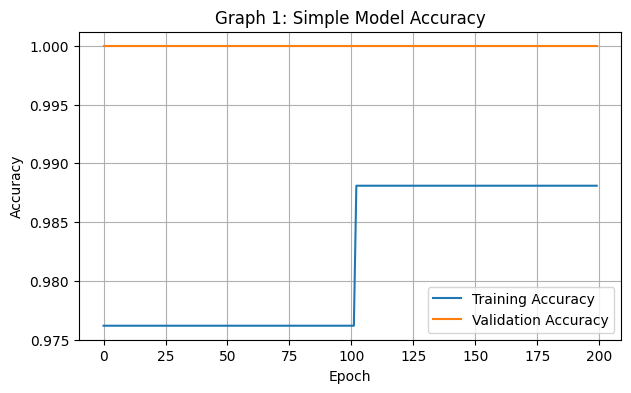

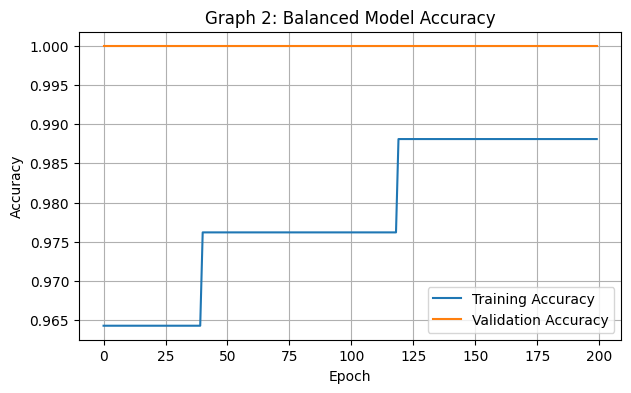

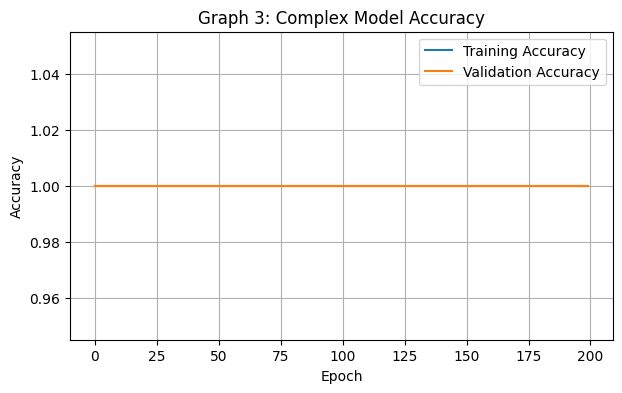

In [37]:

# Graph 1: Simple Model Accuracy
plt.figure(figsize=(7, 4))
plt.plot(histories["Simple Model"].history["accuracy"], label="Training Accuracy")
plt.plot(histories["Simple Model"].history["val_accuracy"], label="Validation Accuracy")
plt.title("Graph 1: Simple Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Graph 2: Balanced Model Accuracy
plt.figure(figsize=(7, 4))
plt.plot(histories["Balanced Model"].history["accuracy"], label="Training Accuracy")
plt.plot(histories["Balanced Model"].history["val_accuracy"], label="Validation Accuracy")
plt.title("Graph 2: Balanced Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Graph 3: Complex Model Accuracy
plt.figure(figsize=(7, 4))
plt.plot(histories["Complex Model"].history["accuracy"], label="Training Accuracy")
plt.plot(histories["Complex Model"].history["val_accuracy"], label="Validation Accuracy")
plt.title("Graph 3: Complex Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()



### **Training and Validation Loss**

Loss measures the difference between predictions and correct labels. Training loss shows the error on training data, while validation loss shows the error on validation data.

If training loss decreases but validation loss starts increasing, overfitting may be occurring. If both losses remain high, the model may be underfitting.


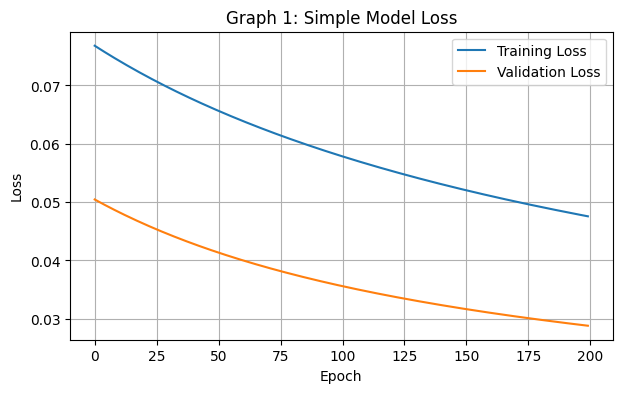

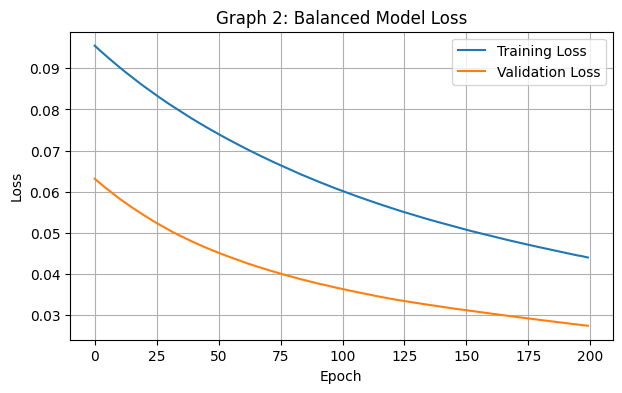

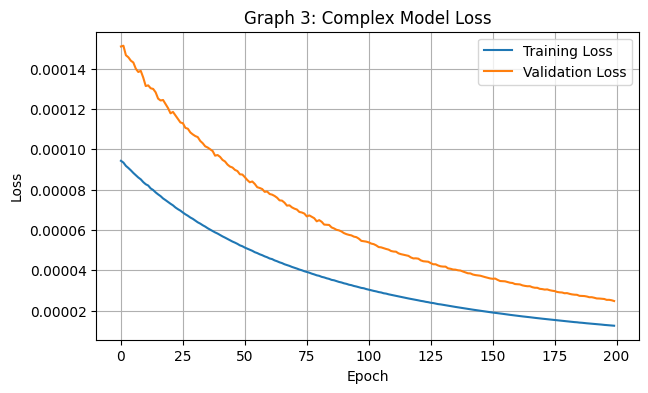

In [38]:

# Graph 1: Simple Model Loss
plt.figure(figsize=(7, 4))
plt.plot(histories["Simple Model"].history["loss"], label="Training Loss")
plt.plot(histories["Simple Model"].history["val_loss"], label="Validation Loss")
plt.title("Graph 1: Simple Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

# Graph 2: Balanced Model Loss
plt.figure(figsize=(7, 4))
plt.plot(histories["Balanced Model"].history["loss"], label="Training Loss")
plt.plot(histories["Balanced Model"].history["val_loss"], label="Validation Loss")
plt.title("Graph 2: Balanced Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

# Graph 3: Complex Model Loss
plt.figure(figsize=(7, 4))
plt.plot(histories["Complex Model"].history["loss"], label="Training Loss")
plt.plot(histories["Complex Model"].history["val_loss"], label="Validation Loss")
plt.title("Graph 3: Complex Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()



### **Testing Accuracy Comparison**

A bar chart compares the testing accuracy of the three neural network models. It helps identify which model performs best on unseen data. The results are interpreted together with training accuracy and loss curves.


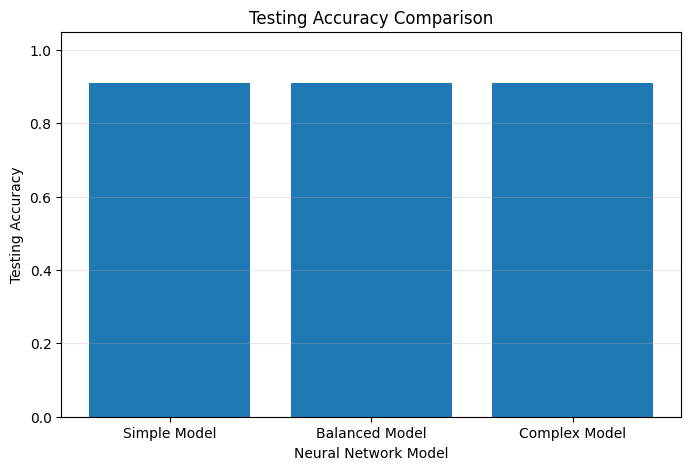

In [39]:
plt.figure(figsize=(8, 5))

plt.bar(results_df["Model"], results_df["Testing Accuracy"])

plt.title("Testing Accuracy Comparison")
plt.xlabel("Neural Network Model")
plt.ylabel("Testing Accuracy")
plt.ylim(0, 1.05)
plt.grid(axis="y", alpha=0.3)

plt.show()


### **Classification Report**

The classification report provides precision, recall, and F1-score for each flower class. These metrics provide additional information about how accurately the models classify Setosa, Versicolor, and Virginica.


In [40]:
for name, model in models.items():
    y_pred = np.argmax(
        model.predict(X_test, verbose=0),
        axis=1
    )

    print("\nClassification Report:", name)

    print(classification_report(
        y_test,
        y_pred,
        target_names=iris.target_names,
        zero_division=0
    ))


Classification Report: Simple Model
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.82      0.93      0.88        15
   virginica       0.92      0.80      0.86        15

    accuracy                           0.91        45
   macro avg       0.92      0.91      0.91        45
weighted avg       0.92      0.91      0.91        45


Classification Report: Balanced Model
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.82      0.93      0.88        15
   virginica       0.92      0.80      0.86        15

    accuracy                           0.91        45
   macro avg       0.92      0.91      0.91        45
weighted avg       0.92      0.91      0.91        45


Classification Report: Complex Model
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor   


# **Task 3: Identify Underfitting, Appropriate Fitting, and Overfitting**

### **Underfitting**
Underfitting occurs when a model is too simple to learn important patterns. It generally shows poor training and testing performance.

### **Appropriate Fitting**
Appropriate fitting occurs when a model learns useful patterns and performs well on both training and testing data, with a reasonably small performance gap.

### **Overfitting**
Overfitting occurs when a model performs very well on training data but noticeably worse on testing data. Increasing validation loss while training loss decreases may also indicate overfitting.

The three models are compared using their accuracy values and learning curves. The actual results are used to determine which fitting behavior each model demonstrates.


In [41]:
for _, row in results_df.iterrows():
    name = row["Model"]
    train_acc = row["Training Accuracy"]
    test_acc = row["Testing Accuracy"]
    gap = train_acc - test_acc

    print("\nModel:", name)
    print(f"Training Accuracy: {train_acc:.2%}")
    print(f"Testing Accuracy:  {test_acc:.2%}")
    print(f"Accuracy Gap:      {gap:.2%}")

    if train_acc < 0.80 and test_acc < 0.80:
        print("Possible underfitting: both accuracies are low.")
    elif gap > 0.10:
        print("Possible overfitting or a generalization gap.")
    else:
        print("Training and testing accuracy are reasonably close.")


Model: Simple Model
Training Accuracy: 99.05%
Testing Accuracy:  91.11%
Accuracy Gap:      7.94%
Training and testing accuracy are reasonably close.

Model: Balanced Model
Training Accuracy: 99.05%
Testing Accuracy:  91.11%
Accuracy Gap:      7.94%
Training and testing accuracy are reasonably close.

Model: Complex Model
Training Accuracy: 100.00%
Testing Accuracy:  91.11%
Accuracy Gap:      8.89%
Training and testing accuracy are reasonably close.



## **Methods to Improve Model Performance**

### **1. Reduce Underfitting**
- Increase the number of neurons.
- Add hidden layers if needed.
- Train for additional epochs when the model has not learned sufficiently.

### **2. Reduce Overfitting**
- Use dropout to reduce dependence on individual neurons.
- Apply L2 regularization to control large weights.
- Use early stopping when validation performance stops improving.
- Collect more training data when possible.

### **3. Improve Generalization**
- Standardize the input features.
- Select a suitable neural network architecture.
- Monitor validation accuracy and loss.
- Evaluate the final model on unseen testing data.



## **Result**

Three neural network models with different architectures were built using the Iris dataset. All models were trained and evaluated using the same training and testing data. Their training accuracy, testing accuracy, validation curves, loss values, and classification reports were compared.

## **Conclusion**

The project demonstrates how neural network complexity affects learning and generalization. A model that is too simple may underfit, while a model that is too complex may overfit. A suitable model should learn meaningful patterns and perform well on unseen data.

Comparing training and testing performance, monitoring validation curves, and applying techniques such as dropout, L2 regularization, and early stopping can help improve model performance.
